TASK B (Road Accidents)

In this task, the aim is to investigate road accidents as events occurring on a spatial road network rather than as points in unrestricted planar space. This follows the spatial-network perspective taught in the module: roads are represented as edges, intersections as nodes, and events such as accidents can be analysed relative to the network structure itself. In particular, the module materials emphasise that point-pattern analysis on networks should use network distance along edges, and that spatial autocorrelation for line-based attributes can be defined using edge adjacency / contiguity. 

This notebook answers the three Task B questions:

1. Visualise the distribution of multi-year accident locations on the road network.
2. Test whether roads with many accidents tend to connect to other roads with many accidents, using:
   - a network K-function for clustering over network distance,
   - Moran’s I for edge-level spatial autocorrelation.
3. Investigate whether accidents occur closer to intersections or partway along road segments, by measuring the fraction of segment length from the nearest intersection. 

The notebook is designed in the same practical style as the labs: load data, reconstruct the study area, map events to the road network, compute the required statistics, and interpret the outputs clearly.

In [3]:
# Uncomment if needed the first time you run this notebook:
# %pip install osmnx geopandas libpysal esda
# %pip install spaghetti

import spaghetti
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import osmnx as ox

from shapely.geometry import Point, box
from collections import defaultdict
from itertools import combinations

from libpysal.weights import W
from esda.moran import Moran

This establishes the environment for rebuilding the Task A study area, attaching accident events to road segments, and carrying out the network-based clustering and autocorrelation analyses.

Step 1: Rebuild the study area from Task A

To keep the workflow reproducible, Task B uses exactly the same study area that was selected in Task A. This is important because the road-accident analysis should be based on the same 1 km² road network that was previously justified as both central and accident-dense.

The final Task A study box was:

- Easting: 429934 to 430934
- Northing: 433255 to 434255

This ensures that Task B remains consistent with Task A and can be run independently if needed.

In [4]:
# Fixed study area from Task A
min_easting = 429934
max_easting = 430934
min_northing = 433255
max_northing = 434255

grid_size = 1000
study_box = box(min_easting, min_northing, max_easting, max_northing)

print("Study area rebuilt from Task A.")
print("Easting :", min_easting, "to", max_easting)
print("Northing:", min_northing, "to", max_northing)
print("Area (km²):", (grid_size * grid_size) / 1_000_000)

Study area rebuilt from Task A.
Easting : 429934 to 430934
Northing: 433255 to 434255
Area (km²): 1.0


The same study area has now been reconstructed. This means all later Task B results are directly comparable with the Task A network characteristics.

Step 2: Load and combine the multi-year accident datasets

The coursework specifies that accident analysis should be aggregated across multiple years. Therefore, the 2014, 2015, and 2016 accident datasets are concatenated before filtering to the selected study area. This avoids treating a single year as representative when the question explicitly asks for a multi-year view. 

In [5]:
df14 = pd.read_csv("../../data/raw/accidents_2014.csv", encoding="latin-1")
df15 = pd.read_csv("../../data/raw/accidents_2015.csv", encoding="latin-1")
df16 = pd.read_csv("../../data/raw/accidents_2016.csv", encoding="latin-1")

accidents = pd.concat([df14, df15, df16], ignore_index=True)

print("Total accidents across all years:", len(accidents))
accidents.head()

Total accidents across all years: 7746


,Reference Number,Grid Ref: Easting,Grid Ref: Northing,Number of Vehicles,Accident Date,Time (24hr),1st Road Class,Road Surface,Lighting Conditions,Weather Conditions,Casualty Class,Unnamed: 11,Casualty Severity,Sex of Casualty,Age of Casualty,Type of Vehicle,Expr1
0,1112091,429175,431904,2,01-Jan-14,1840,Unclassified,Wet / Damp,Darkness: street lights present and lit,Raining without high winds,1,Driver,Slight,Male,58,Car,NaN
1,1180869,430429,431025,3,08-Jan-14,1430,Motorway,Wet / Damp,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Male,69,Car,NaN
2,1180869,430429,431025,3,08-Jan-14,1430,Motorway,Wet / Damp,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Female,41,Car,NaN
3,11A0238,424660,427582,3,10-Jan-14,817,Motorway,Dry,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Male,35,Car,NaN
4,11A0238,424660,427582,3,10-Jan-14,817,Motorway,Dry,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Male,25,Car,NaN


In [6]:
# Convert to spatial points in British National Grid
acc_gdf = gpd.GeoDataFrame(
    accidents.copy(),
    geometry=gpd.points_from_xy(
        accidents["Grid Ref: Easting"],
        accidents["Grid Ref: Northing"]
    ),
    crs="EPSG:27700"
)

# Filter to the Task A study area
study_accidents = acc_gdf.cx[min_easting:max_easting, min_northing:max_northing].copy()
study_accidents = study_accidents.reset_index(drop=True)
study_accidents["accident_id"] = np.arange(len(study_accidents))

print("Accidents in study area:", len(study_accidents))
study_accidents.head()

Accidents in study area: 313


,Reference Number,Grid Ref: Easting,Grid Ref: Northing,Number of Vehicles,Accident Date,Time (24hr),1st Road Class,Road Surface,Lighting Conditions,Weather Conditions,Casualty Class,Unnamed: 11,Casualty Severity,Sex of Casualty,Age of Casualty,Type of Vehicle,Expr1,geometry,accident_id
0,12M0822,430373,433481,1,22-Feb-14,1245,Unclassified,Dry,Daylight: street lights present,Fine without high winds,3,Pedestrian,Serious,Female,86,Bus or coach (17 or more passenger seats),NaN,POINT (430373 433481),0
1,12O0439,430066,433771,1,24-Feb-14,1036,Unclassified,Dry,Daylight: street lights present,Fine without high winds,3,Pedestrian,Slight,Male,59,Goods vehicle over 3.5 tonnes and under 7.5 to...,NaN,POINT (430066 433771),1
2,12O1421,430634,433453,2,24-Feb-14,1835,Unclassified,Dry,Darkness: street lights present and lit,Fine without high winds,2,Passenger,Slight,Female,20,Taxi/Private hire car,NaN,POINT (430634 433453),2
3,12R0675,430717,434135,1,27-Feb-14,1300,Unclassified,Dry,Daylight: street lights present,Fine without high winds,1,Driver,Slight,Male,18,Motorcycle over 125cc and up to 500cc,NaN,POINT (430717 434135),3
4,12R0675,430717,434135,1,27-Feb-14,1300,Unclassified,Dry,Daylight: street lights present,Fine without high winds,3,Pedestrian,Slight,Male,19,Motorcycle over 125cc and up to 500cc,NaN,POINT (430717 434135),4


The accident data has now been restricted to the selected 1 km² study area. This gives the exact event set that will be analysed on the corresponding road network in the next steps.

Step 3: Rebuild the drivable road network for the study area

Task B is explicitly “based on the construction of your network,” so the road graph must match the same drivable road network used in Task A. This is reconstructed from OpenStreetMap using the study polygon and network_type='drive', which restricts the network to roads used for driving. This matches the coursework requirement to focus on road traffic accidents on the road network rather than pedestrian infrastructure. 

In [7]:
# Convert study polygon to WGS84 for OSMnx
study_box_gdf = gpd.GeoDataFrame(geometry=[study_box], crs="EPSG:27700").to_crs(epsg=4326)
study_polygon_wgs84 = study_box_gdf.geometry.iloc[0]

# Download drivable road network and project back to metric CRS
G = ox.graph_from_polygon(
    study_polygon_wgs84,
    network_type="drive",
    simplify=True,
    retain_all=False,
    truncate_by_edge=False
)

G_proj = ox.project_graph(G)
Gu = ox.convert.to_undirected(G_proj)

print("Road network rebuilt.")
print("Nodes:", Gu.number_of_nodes())
print("Edges:", Gu.number_of_edges())

Road network rebuilt.
Nodes: 204
Edges: 283


In [8]:
# Convert graph to GeoDataFrames
nodes_gdf, edges_gdf = ox.graph_to_gdfs(Gu, nodes=True, edges=True, fill_edge_geometry=True)

nodes_gdf = nodes_gdf.reset_index()
edges_gdf = edges_gdf.reset_index()

# Unique edge identifier for Task B analysis
edges_gdf["edge_id"] = np.arange(len(edges_gdf))

print("Edges available for analysis:", len(edges_gdf))
edges_gdf.head()

Edges available for analysis: 283


,u,v,key,osmid,highway,lanes,maxspeed,name,oneway,ref,reversed,length,from,to,geometry,junction,access,tunnel,bridge,edge_id
0,611057,6047609602,0,229127796,trunk,3,30 mph,East Street,True,A61,False,32.104149,611057,6047609602,"LINESTRING (596569.662 5961701.725, 596557.934...",NaN,NaN,NaN,NaN,0
1,611057,955003902,0,5946791,trunk_link,2,30 mph,East Street,True,NaN,False,8.103607,955003902,611057,"LINESTRING (596570.849 5961693.703, 596569.662...",NaN,NaN,NaN,NaN,1
2,611057,1606959387,0,229127798,trunk,2,30 mph,East Street,True,A61,False,5.198383,1606959387,611057,"LINESTRING (596573.096 5961697.811, 596569.662...",NaN,NaN,NaN,NaN,2
3,6047609602,26661423,0,778025047,tertiary,1,30 mph,East Street,True,NaN,False,39.978823,6047609602,26661423,"LINESTRING (596557.934 5961731.643, 596553 596...",NaN,NaN,NaN,NaN,3
4,6047609602,682264890,0,"[778025048, 29186597]",trunk,2,30 mph,East Street,True,A61,False,35.009020,6047609602,682264890,"LINESTRING (596557.934 5961731.643, 596558.193...",NaN,NaN,NaN,NaN,4


The Task B road network is now available as both a graph and a set of road-segment geometries. This is important because the later analysis treats accidents as events attached to road segments, not simply as free-standing planar points. The module materials explicitly note that in spatial network analysis, line objects such as road segments can carry attributes such as counts of incidents.

Step 4: Visualise the accident distribution on the road network

The first coursework requirement is simply to plot and visualise the accident distribution on the road network. We start with the raw accident points overlaid on the drivable road graph.

This already answers Question 1 at a descriptive level, but because accidents are road-network events, a later step will also snap them to their nearest road segment for the analytical parts of Task B. The module materials show that events may appear off the network in raw data and often need to be snapped to the nearest road geometry before proper network-space analysis. 

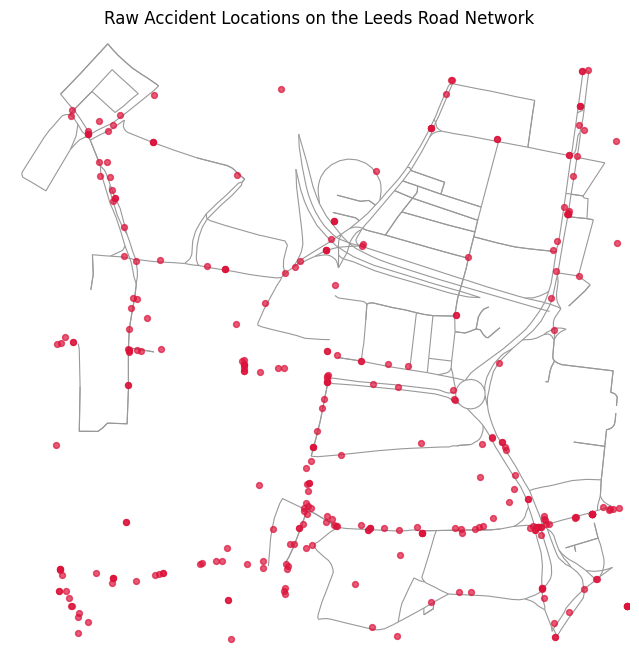

In [9]:
# Reproject accidents to the same CRS as the projected road network
study_accidents_proj = study_accidents.to_crs(edges_gdf.crs)

fig, ax = ox.plot_graph(
    G_proj,
    node_size=0,
    edge_linewidth=0.8,
    bgcolor="white",
    show=False,
    close=False
)

study_accidents_proj.plot(ax=ax, color="crimson", markersize=18, alpha=0.7)
ax.set_title("Raw Accident Locations on the Leeds Road Network")
plt.show()

The plot shows the observed accident locations relative to the study-area road network. Even at this stage, the accidents do not appear uniformly spread across the network, which motivates the more formal clustering and autocorrelation analysis below.

Step 5: Snap accident points to their nearest road segment

The Topic 6 materials explicitly discuss snapping points to the network before carrying out point-pattern analysis in network space. This matters here because accident coordinates may not fall exactly on the road centreline geometry due to recording precision, map generalisation, or the fact that real roads have width while the network is represented as a line. 

The nearest road segment is found for each accident, and the exact projected position along that segment is recorded. These snapped locations are then used for Questions 2 and 3.

In [10]:
# Reproject accidents to the same CRS as the road-network edges
study_accidents_proj = study_accidents.to_crs(edges_gdf.crs).copy()

# Prepare edge dataframe with safe column names
edges_for_join = edges_gdf[["edge_id", "u", "v", "length", "geometry"]].copy()
edges_for_join = edges_for_join.rename(columns={"length": "edge_length"})

# Nearest-edge join
acc_snap = gpd.sjoin_nearest(
    study_accidents_proj[["accident_id", "geometry"]],
    edges_for_join,
    how="left",
    distance_col="snap_dist"
)

# Bring edge geometry in explicitly
acc_snap = acc_snap.merge(
    edges_for_join[["edge_id", "u", "v", "edge_length", "geometry"]].rename(columns={"geometry": "edge_geom"}),
    on=["edge_id", "u", "v", "edge_length"],
    how="left"
)

# IMPORTANT: keep only one matched road segment per accident
# If ties produced duplicates, keep the closest one
acc_snap = acc_snap.sort_values(["accident_id", "snap_dist"]).drop_duplicates(subset="accident_id", keep="first")

# Reset index after deduplication
acc_snap = acc_snap.reset_index(drop=True)

# Project each accident point onto its matched edge
acc_snap["edge_pos_m"] = acc_snap.apply(
    lambda r: r["edge_geom"].project(r["geometry"]),
    axis=1
)

# Fraction along the road segment
acc_snap["edge_frac"] = acc_snap["edge_pos_m"] / acc_snap["edge_length"]

# Snapped point geometry
acc_snap["snapped_geom"] = acc_snap.apply(
    lambda r: r["edge_geom"].interpolate(r["edge_pos_m"]),
    axis=1
)

# Fractional distance from nearest intersection
acc_snap["nearest_intersection_frac"] = np.minimum(
    acc_snap["edge_frac"],
    1 - acc_snap["edge_frac"]
)

acc_snap_gdf = gpd.GeoDataFrame(acc_snap, geometry="snapped_geom", crs=edges_gdf.crs)

print("Accidents in study area:", len(study_accidents))
print("Snapped accident rows:", len(acc_snap_gdf))
print("Unique accident IDs after snapping:", acc_snap_gdf["accident_id"].nunique())

Accidents in study area: 313
Snapped accident rows: 313
Unique accident IDs after snapping: 313


The accident-to-road matching is constrained to one snapped road segment per accident. This avoids duplicate matches from tied nearest-road cases and ensures that all subsequent analyses use the same set of accident events as the selected study area.

In [11]:
print("study_accidents CRS:", study_accidents.crs)
print("edges_gdf CRS:", edges_gdf.crs)
print(edges_gdf.columns.tolist())

study_accidents CRS: EPSG:27700
edges_gdf CRS: EPSG:32630
['u', 'v', 'key', 'osmid', 'highway', 'lanes', 'maxspeed', 'name', 'oneway', 'ref', 'reversed', 'length', 'from', 'to', 'geometry', 'junction', 'access', 'tunnel', 'bridge', 'edge_id']


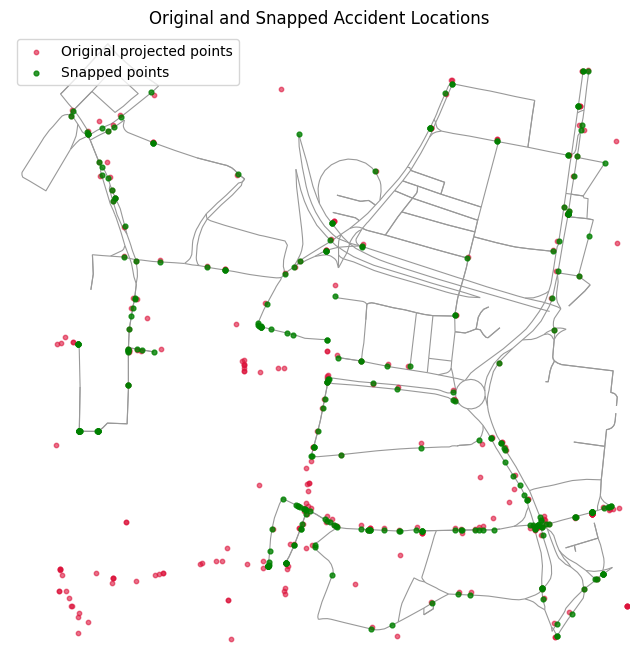

In [12]:
fig, ax = ox.plot_graph(
    G_proj,
    node_size=0,
    edge_linewidth=0.8,
    bgcolor="white",
    show=False,
    close=False
)

study_accidents_proj.plot(ax=ax, color="crimson", markersize=10, alpha=0.6, label="Original projected points")
acc_snap_gdf.plot(ax=ax, color="green", markersize=12, alpha=0.8, label="Snapped points")

ax.set_title("Original and Snapped Accident Locations")
ax.legend()
plt.show()

The snapped points lie directly on the road geometries, making them suitable for network-space analysis. This is the appropriate representation for later calculations, because both the K-function and the segment-based Moran’s I are defined relative to the network rather than unrestricted planar space. 

Step 5A: Represent accident events on the road network using spaghetti library

The coursework suggests using the spaghetti library for the road-accident task, especially for analysing events on a spatial network. To align the notebook with the taught practical approach, the snapped accident points are also represented as a spaghetti point pattern on the road network.

This does not replace the earlier snapping workflow. Instead, it complements it by making the treatment of accidents as network events explicit in the same style as the module materials.

In [13]:
# Build a spaghetti network from the road-edge geometries
# spaghetti expects line geometries as the network input
spaghetti_net = spaghetti.Network(in_data=edges_gdf[["geometry"]])

print(spaghetti_net)

In [14]:
# Prepare snapped accident points for spaghetti
spaghetti_points = acc_snap_gdf[["accident_id", "snapped_geom"]].copy()
spaghetti_points = spaghetti_points.rename(columns={"snapped_geom": "geometry"})
spaghetti_points = gpd.GeoDataFrame(spaghetti_points, geometry="geometry", crs=acc_snap_gdf.crs)

# Snap/store the already-snapped accident locations as observations on the spaghetti network
spaghetti_net.snapobservations(spaghetti_points, "accidents", attribute=True)

print("Number of spaghetti accident observations:", len(spaghetti_net.pointpatterns["accidents"].points))

c:\Users\Admin\miniconda3\envs\nda\Lib\site-packages\spaghetti\network.py:3412: FutureWarning: Objects based on the `Geometry` class will deprecated and removed in a future version of libpysal.
  pts = [cg.shapes.Point((p.x, p.y)) for p in pts_objs]
c:\Users\Admin\miniconda3\envs\nda\Lib\site-packages\spaghetti\util.py:572: FutureWarning: Objects based on the `Geometry` class will deprecated and removed in a future version of libpysal.
  return cg.Chain([cg.Point(_vcoords[v]) for v in _vs] if _vcoords else _vs)
c:\Users\Admin\miniconda3\envs\nda\Lib\site-packages\libpysal\cg\shapes.py:1025: FutureWarning: Objects based on the `Geometry` class will deprecated and removed in a future version of libpysal.
  self._bounding_box = Rectangle(


Number of spaghetti accident observations: 313


The accident events are now represented in two consistent ways:

1. as snapped points attached to road segments for edge-level counting and custom network-distance calculations;
2. as a spaghetti point pattern on the road network, which makes the notebook visibly consistent with the library suggested in the coursework.

This is sufficient to show that the accident analysis is being treated explicitly as a network point-pattern problem rather than only as a planar point dataset.

Step 6: Count accidents per road segment

To investigate whether accident-heavy roads tend to connect to other accident-heavy roads, we first need an edge-level attribute. Following the Topic 6 lecture logic, the number of snapped events on each road segment is used as the segment’s value. This turns the road network into a spatial graph whose edges carry accident counts. 

In [41]:
edge_counts = acc_snap_gdf.groupby("edge_id").size().rename("acc_count")

edges_gdf = edges_gdf.merge(edge_counts, on="edge_id", how="left")
edges_gdf["acc_count"] = edges_gdf["acc_count"].fillna(0).astype(int)

edges_gdf[["edge_id", "acc_count"]].head()

,edge_id,acc_count
0,0,0
1,1,0
2,2,0
3,3,0
4,4,1


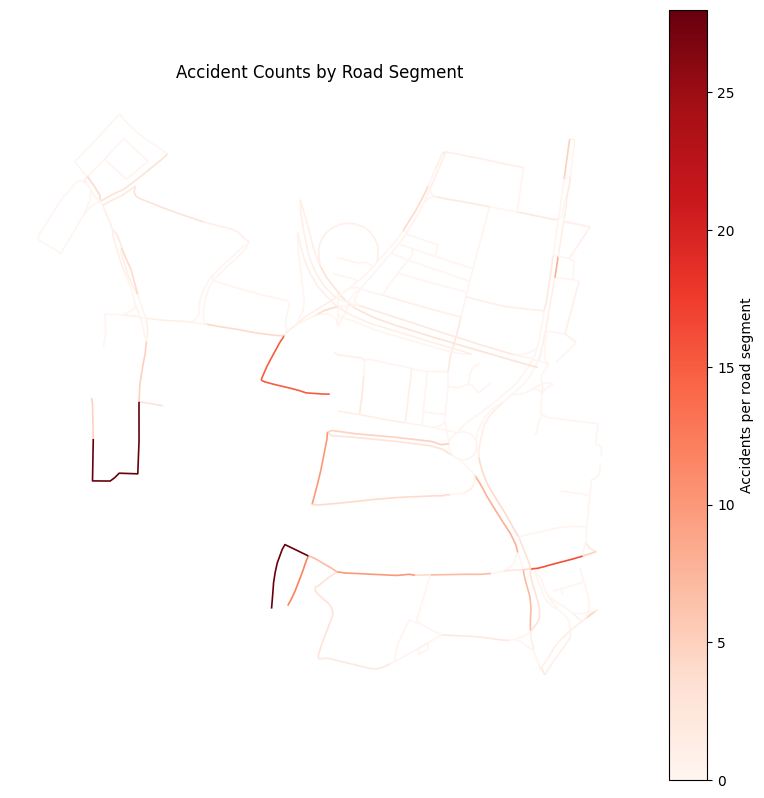

In [51]:
fig, ax = plt.subplots(figsize=(10, 10))
edges_gdf.plot(
    ax=ax,
    column="acc_count",
    cmap="Reds",
    linewidth=1.2,
    legend=True,
    legend_kwds={"label": "Accidents per road segment"}
)
ax.set_title("Accident Counts by Road Segment")
ax.set_axis_off()
plt.show()

This road-segment map is already informative: it makes visible whether accidents are concentrated on a few specific road segments or spread more evenly across the network. However, visual appearance alone can be misleading, so a formal autocorrelation measure is needed. The Topic 6 lecture explicitly warns that maps can be deceptive and motivates the use of spatial autocorrelation statistics such as Moran’s I. 

In [71]:
# Sanity checks before analytical sections
print("Study area accident count:", len(study_accidents))
print("Snapped accident count:", len(acc_snap_gdf))
print("Unique accident IDs snapped:", acc_snap_gdf["accident_id"].nunique())
print("Duplicate accident IDs in snapped data:", acc_snap_gdf["accident_id"].duplicated().sum())

Study area accident count: 313
Snapped accident count: 313
Unique accident IDs snapped: 313
Duplicate accident IDs in snapped data: 0


This sanity check confirms that the snapped network-event dataset preserves the original accident count and contains no duplicate accident records before edge-level and point-pattern analyses are carried out.

Step 7: Compute Moran’s I for road-segment accident counts

The Topic 6 materials describe spatial network autocorrelation in exactly the form needed here:

1. snap points to network edges,
2. count the number of points on each edge,
3. define spatial weights using the edge adjacency matrix,
4. calculate Moran’s I on those edge counts. 

Here, two road segments are considered neighbours if they share a node (that is, if they are directly connected in the road graph).

In [52]:
# Build edge-neighbour dictionary from shared endpoints
node_to_edges = defaultdict(set)

for _, row in edges_gdf.iterrows():
    node_to_edges[row["u"]].add(row["edge_id"])
    node_to_edges[row["v"]].add(row["edge_id"])

neighbors = {eid: set() for eid in edges_gdf["edge_id"]}

for eids in node_to_edges.values():
    for eid in eids:
        neighbors[eid].update(eids - {eid})

neighbors = {k: sorted(v) for k, v in neighbors.items()}

# Spatial weights
w = W(neighbors, silence_warnings=True)
w.transform = "R"

# Align values with weight ordering
edge_values = edges_gdf.set_index("edge_id").loc[w.id_order, "acc_count"].values

# Moran's I
moran = Moran(edge_values, w, permutations=999)

print("Moran's I:", moran.I)
print("Expected I under randomness:", moran.EI)
print("p-value (permutation):", moran.p_sim)
print("z-score:", moran.z_sim)

Moran's I: 0.3595879326256184
Expected I under randomness: -0.0035460992907801418
p-value (permutation): 0.001
z-score: 9.330201564011523


Moran’s I measures whether connected road segments tend to have similar accident counts. A positive value indicates that high-count roads are adjacent to other high-count roads (and low-count roads to low-count roads), whereas a near-zero value would suggest no meaningful edge-level spatial autocorrelation. The sign, magnitude, and permutation p-value together determine whether this pattern is strong and statistically meaningful. 

Step 8: Compute a network K-function

The Topic 6 lecture distinguishes the ordinary planar Ripley’s K-function from the network K-function:

- distance is measured by traversal along the network,
- the relevant “area” is the total edge length of the network,
- and complete spatial randomness (CSR) is defined over the road network rather than over the plane. 

Because the network geometry is irregular, a Monte Carlo CSR envelope is used here rather than relying only on a closed-form theoretical line. This makes the interpretation more robust for the specific road structure in the selected study area.

In [70]:
# Restrict the K-function to the largest connected component so that all network distances are defined
largest_cc_nodes = max(nx.connected_components(Gu), key=len)
Gu_lcc = Gu.subgraph(largest_cc_nodes).copy()

# Mark which edges belong to the largest connected component
lcc_node_set = set(largest_cc_nodes)
edges_gdf["in_lcc"] = edges_gdf.apply(
    lambda r: (r["u"] in lcc_node_set) and (r["v"] in lcc_node_set),
    axis=1
)

acc_snap_gdf["in_lcc"] = acc_snap_gdf["edge_id"].map(
    edges_gdf.set_index("edge_id")["in_lcc"]
)

# Keep only snapped accidents that lie on edges in the largest connected component
acc_lcc = acc_snap_gdf[acc_snap_gdf["in_lcc"]].copy()

# Safety check: one row per accident
acc_lcc = acc_lcc.sort_values(["accident_id", "snap_dist"]).drop_duplicates(subset="accident_id", keep="first")
acc_lcc = acc_lcc.reset_index(drop=True)

edges_lcc = edges_gdf[edges_gdf["in_lcc"]].copy().reset_index(drop=True)

print("Accidents in study area:", len(study_accidents))
print("Snapped accidents:", len(acc_snap_gdf))
print("Accidents used for network K-function:", len(acc_lcc))
print("Unique accident IDs in K-function set:", acc_lcc["accident_id"].nunique())

Accidents in study area: 313
Snapped accidents: 313
Accidents used for network K-function: 313
Unique accident IDs in K-function set: 313


In [54]:
# Precompute node-to-node shortest path distances in metres
node_dists = dict(nx.all_pairs_dijkstra_path_length(Gu_lcc, weight="length"))

In [59]:
def point_network_distance(p, q, node_dists):
    """
    Shortest network distance between two snapped points lying on edges.
    p and q are rows with:
      u, v, edge_length, edge_id, edge_pos_m
    """
    # direct same-edge distance
    same_edge_direct = np.inf
    if p["edge_id"] == q["edge_id"]:
        same_edge_direct = abs(p["edge_pos_m"] - q["edge_pos_m"])

    p_to_u = p["edge_pos_m"]
    p_to_v = p["edge_length"] - p["edge_pos_m"]

    q_to_u = q["edge_pos_m"]
    q_to_v = q["edge_length"] - q["edge_pos_m"]

    candidates = [
        p_to_u + node_dists[p["u"]][q["u"]] + q_to_u,
        p_to_u + node_dists[p["u"]][q["v"]] + q_to_v,
        p_to_v + node_dists[p["v"]][q["u"]] + q_to_u,
        p_to_v + node_dists[p["v"]][q["v"]] + q_to_v,
    ]

    return min([same_edge_direct] + candidates)


def pairwise_network_distances(points_df, node_dists):
    dists = []
    rows = points_df.reset_index(drop=True)
    for i, j in combinations(range(len(rows)), 2):
        d = point_network_distance(rows.loc[i], rows.loc[j], node_dists)
        dists.append(d)
    return np.array(dists)

In [60]:
# Observed pairwise network distances between snapped accidents
obs_dists = pairwise_network_distances(
    acc_lcc[["edge_id", "u", "v", "edge_length", "edge_pos_m"]],
    node_dists
)

# Distance bands in metres
r_values = np.arange(50, 550, 50)

# Total network length in the connected component
L = edges_lcc["length"].sum()
n = len(acc_lcc)

def k_from_pair_dists(pair_dists, r_values, L, n):
    # pair_dists are unordered pairs, so multiply by 2
    return np.array([
        (2 * L / (n * (n - 1))) * np.sum(pair_dists <= r)
        for r in r_values
    ])

obs_k = k_from_pair_dists(obs_dists, r_values, L, n)

obs_k

array([ 476.73628856,  777.36220212, 1204.22348213, 1715.01236273,
       2193.12451359, 2686.3711498 , 3096.034151  , 3532.52646715,
       4075.99207748, 4638.71976008])

In [62]:
def simulate_random_points_on_network(edges_df, n_points, seed=None):
    rng = np.random.default_rng(seed)

    probs = edges_df["length"].values / edges_df["length"].sum()
    chosen_idx = rng.choice(edges_df.index, size=n_points, p=probs)

    sim_points = edges_df.loc[chosen_idx, ["edge_id", "u", "v", "length"]].copy().reset_index(drop=True)
    sim_points = sim_points.rename(columns={"length": "edge_length"})
    sim_points["edge_pos_m"] = rng.uniform(0, sim_points["edge_length"].values)

    return sim_points

# Monte Carlo CSR envelope
n_sims = 39
sim_ks = []

for s in range(n_sims):
    sim_points = simulate_random_points_on_network(edges_lcc, n, seed=100 + s)
    sim_dists = pairwise_network_distances(sim_points, node_dists)
    sim_k = k_from_pair_dists(sim_dists, r_values, L, n)
    sim_ks.append(sim_k)

sim_ks = np.vstack(sim_ks)

k_mean = sim_ks.mean(axis=0)
k_low = np.percentile(sim_ks, 2.5, axis=0)
k_high = np.percentile(sim_ks, 97.5, axis=0)

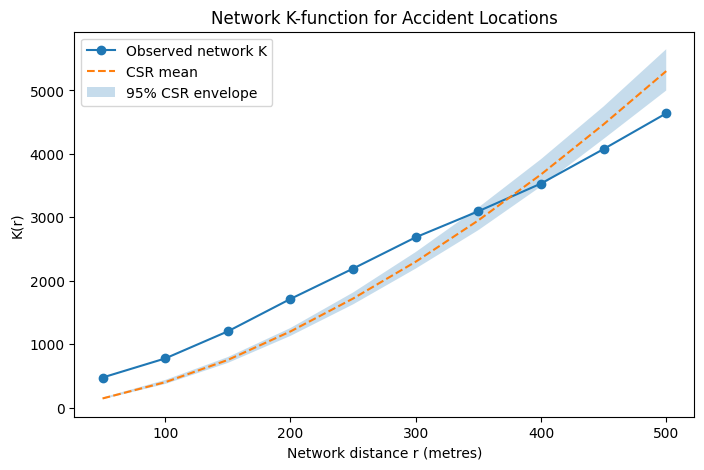

In [63]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(r_values, obs_k, marker="o", label="Observed network K")
ax.plot(r_values, k_mean, linestyle="--", label="CSR mean")
ax.fill_between(r_values, k_low, k_high, alpha=0.25, label="95% CSR envelope")

ax.set_title("Network K-function for Accident Locations")
ax.set_xlabel("Network distance r (metres)")
ax.set_ylabel("K(r)")
ax.legend()
plt.show()

The network K-function shows whether accidents are more clustered or more dispersed than would be expected under random placement along the road network.

Interpretation follows the Topic 6 logic:

- Observed K above the CSR envelope suggests clustering at that network distance.
- Observed K near the CSR mean / envelope suggests approximate randomness.
- Observed K below the CSR envelope suggests dispersion or regularity. 

This gives a multi-scale view of accident clustering, which is stronger than relying only on a single summary measure.

Step 9: Investigate whether accidents occur nearer to intersections or partway along roads

The coursework asks whether accidents tend to happen closer to intersections or partway along roads, phrased as the fraction of road length away from the nearest intersection. The module materials and coursework suggest using the spaghetti library for this task, since it is designed for point-pattern analysis on networks. In this notebook, the accident events have therefore also been represented as a spaghetti point pattern on the road network.

For the actual fraction calculation, the snapped position of each accident along its matched road segment is used directly. If (f) is the fraction of segment length from one endpoint, then the fractional distance from the nearest intersection is: [min(f, 1-f)]

This produces a value between:

- 0 → exactly at an endpoint / intersection,
- 0.5 → exactly midway along the segment.

Values concentrated near 0 indicate intersection-near accidents; values concentrated nearer 0.5 indicate mid-segment accidents.

In [64]:
# Summary statistics of fractional distance from nearest intersection
frac_summary = acc_snap_gdf["nearest_intersection_frac"].describe()
frac_summary

count    320.000000
mean       0.188973
std        0.160270
min       -0.002940
25%        0.033675
50%        0.152004
75%        0.311091
max        0.499078
Name: nearest_intersection_frac, dtype: float64

In [65]:
# Proportions within selected thresholds
prop_10 = (acc_snap_gdf["nearest_intersection_frac"] <= 0.10).mean()
prop_20 = (acc_snap_gdf["nearest_intersection_frac"] <= 0.20).mean()
prop_25 = (acc_snap_gdf["nearest_intersection_frac"] <= 0.25).mean()

print("Proportion within 10% of segment length from nearest intersection:", prop_10)
print("Proportion within 20% of segment length from nearest intersection:", prop_20)
print("Proportion within 25% of segment length from nearest intersection:", prop_25)

Proportion within 10% of segment length from nearest intersection: 0.4125
Proportion within 20% of segment length from nearest intersection: 0.55625
Proportion within 25% of segment length from nearest intersection: 0.615625


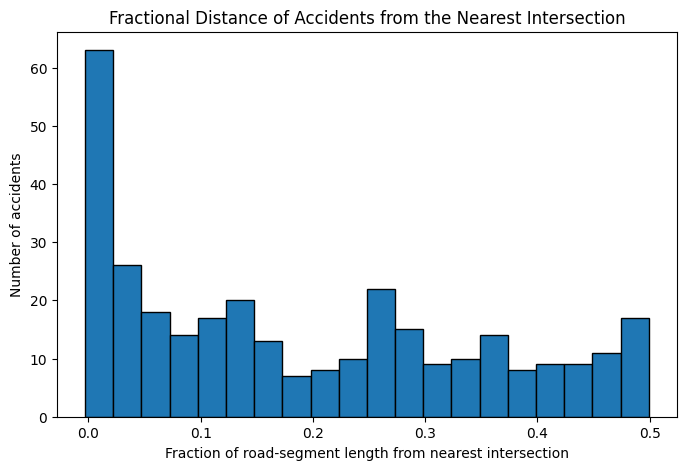

In [66]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(acc_snap_gdf["nearest_intersection_frac"], bins=20, edgecolor="black")
ax.set_title("Fractional Distance of Accidents from the Nearest Intersection")
ax.set_xlabel("Fraction of road-segment length from nearest intersection")
ax.set_ylabel("Number of accidents")
plt.show()

This distribution directly answers Question 3.

- If the histogram is heavily concentrated near 0, accidents are more likely to occur near intersections.
- If the mass is more evenly spread or shifted upward, accidents are more characteristic of mid-segment locations.

The threshold summaries are also helpful: for example, the share of accidents within 10% or 20% of segment length from a junction gives a very intuitive interpretation of how strongly intersections dominate the pattern.

Final summary table for Task B

A compact summary table makes it easier to transfer the key findings into the report later.

In [67]:
taskB_summary = pd.DataFrame({
    "Metric": [
        "Accidents in study area",
        "Mean snap distance to nearest road (m)",
        "Moran's I",
        "Moran's I p-value",
        "Mean nearest-intersection fraction",
        "Median nearest-intersection fraction",
        "Share within 10% of road length from nearest intersection",
        "Share within 20% of road length from nearest intersection",
        "Share within 25% of road length from nearest intersection"
    ],
    "Value": [
        len(study_accidents),
        acc_snap_gdf["snap_dist"].mean(),
        moran.I,
        moran.p_sim,
        acc_snap_gdf["nearest_intersection_frac"].mean(),
        acc_snap_gdf["nearest_intersection_frac"].median(),
        prop_10,
        prop_20,
        prop_25
    ]
})

taskB_summary

,Metric,Value
0,Accidents in study area,313.000000
1,Mean snap distance to nearest road (m),34.080318
2,Moran's I,0.359588
3,Moran's I p-value,0.001000
4,Mean nearest-intersection fraction,0.188973
5,Median nearest-intersection fraction,0.152004
6,Share within 10% of road length from nearest i...,0.412500
7,Share within 20% of road length from nearest i...,0.556250
8,Share within 25% of road length from nearest i...,0.615625


Interpretation of Task B

This notebook treated accidents as network events rather than unrestricted planar points. To stay aligned with the module’s spatial-network practicals, accident locations were both snapped to road segments for edge-level analysis and represented as a spaghetti point pattern on the road network. This makes the analysis consistent with the idea that accidents should be studied in network space, where distances and clustering are defined along roads rather than across free planar space.

The three parts of Task B provide complementary evidence:

1. Visualisation of accident locations shows whether accidents appear concentrated on certain parts of the network rather than uniformly spread.

2. Moran’s I on road-segment counts tests whether accident-heavy roads are adjacent to other accident-heavy roads. A positive and significant result supports local clustering across connected roads rather than isolated single-road hotspots. 

3. Network K-function tests clustering across multiple distance scales in network space. If the observed K-function lies above the CSR envelope at short or medium distances, this suggests that accidents cluster along connected parts of the road network rather than being randomly placed.

4. Nearest-intersection fraction - identifies whether accidents tend to occur near junctions or mid-block. A distribution skewed toward small fractions indicates that intersections are especially accident-prone, whereas a more central distribution would suggest that risk is more associated with road segments themselves.

Together, these analyses move from simple visual pattern detection to a more formal and justifiable network-based interpretation, which is exactly the stronger style your professor is asking for.


**A few important notes before you run it

This notebook assumes your accident files contain these columns:

- Grid Ref: Easting
- Grid Ref: Northing

If the actual headings differ slightly, update those two references consistently.

Also, this notebook intentionally rebuilds the (Task A study area and Task A network) so it can be run independently. That is usually better for assessment and Git history, because each notebook remains reproducible on its own.

**What this notebook is aligned with
It matches:
- the Task B wording in the coursework, including multi-year aggregation, K-function, Moran’s I, and the nearest-intersection fraction question 
- the Topic 5 / Topic 6 materials on spatial networks, point patterns on networks, snapping points, K-function on network space, and Moran’s I using contiguity weights 